# Quantum Volume

In [1]:
# (C) Copyright IBM 2026.
#
# This code is licensed under the Apache License, Version 2.0. You may
# obtain a copy of this license in the LICENSE.txt file in the root directory
# of this source tree or at http://www.apache.org/licenses/LICENSE-2.0.
#
# Any modifications or derivative works of this code must retain this
# copyright notice, and modified files need to carry a notice indicating
# that they have been altered from the originals.

In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [58]:
import warnings
warnings.filterwarnings("ignore")
%config IPCompleter.greedy = True
%config Completer.use_jedi = False
import qiskit

from collections import Counter

from qiskit.visualization import timeline_drawer

from qiskit.circuit import QuantumRegister, ClassicalRegister, Instruction
from qiskit.circuit.library import XGate, Barrier, Measure, RZGate

from qiskit.compiler import transpile
from qiskit.transpiler import PassManager, Layout, CouplingMap
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.transpiler import PassManager
from qiskit.transpiler.instruction_durations import InstructionDurations

from qiskit.result import Counts, Result

from qiskit.quantum_info import Statevector
from qiskit import qpy
from qiskit_ibm_runtime import QiskitRuntimeService, Batch, Session, SamplerV2 as Sampler

import copy
import re
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append('../')
sys.path.append('../../')
import mapomatic as mm

import fastmap
from scipy.special import erf

print(f'Qiskit version: {qiskit.__version__}')

Qiskit version: 2.6.2


In [ ]:
backend_name= 'ibm_phoenix'
service = QiskitRuntimeService(
    channel="ibm_cloud",
    instance="",
    token="", # (your API key),
)
backend = service.backend(backend_name,use_fractional_gates=True)


qiskit_runtime_service._discover_account:WARNING:2026-11-14 14:29:56,771: Loading account with the given token. A saved account will not be used.


##### Load pre-mapped circuits


In [ ]:
## load original, bare circuits
with open('../Top_QV_circuits/qv1024_orig.qpy', 'rb') as f:
    circuits_orig = qpy.load(f)

##load circuits Reinforcement Learning optimized for grid,
with open('../Top_QV_circuits/qv1024_4x4grid_RL.qpy', 'rb') as f:
    circuits_grid = qpy.load(f)

for i,cir in enumerate(circuits_grid):
    cir.name = 'qv_depth_10_trial_' + str(i)

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import Gate
def add_X_measure(qc: QuantumCircuit) -> QuantumCircuit:
    # Work on a copy so as not to modify the original circuit.
    new_qc = qc.copy()

    # Collect measurement instructions (and assume they form one group).
    measurement_indices = []  # list of tuples (instruction index, measured qubit)
    for idx, (instr, qargs, cargs) in enumerate(new_qc.data):
        if instr.name == 'measure' or instr.name=='measure_terminal':
            measurement_indices.append((idx, qargs[0]))

    # Group consecutive measurement instructions.
    measurement_groups = []
    current_group = []
    previous_idx = None
    for idx, qubit in measurement_indices:
        if previous_idx is None or idx == previous_idx + 1:
            current_group.append((idx, qubit))
        else:
            measurement_groups.append(current_group)
            current_group = [(idx, qubit)]
        previous_idx = idx
    if current_group:
        measurement_groups.append(current_group)

    # For simplicity, work with the first measurement group.
    group = measurement_groups[0]
    # Get the ordered list of unique qubits measured.
    ordered_qubits = []
    for _, qubit in group:
        if qubit not in ordered_qubits:
            ordered_qubits.append(qubit)

    new_qc.barrier()
    # Append the xslow gate for each measured qubit.
    for qubit in ordered_qubits:
        new_qc.x([qubit])
    new_qc.barrier()
    # Create a new classical register for the second measurement layer.
    new_cr = ClassicalRegister(len(ordered_qubits), 'cr2')
    new_qc.add_register(new_cr)

    # Append the second measurement layer: measure each qubit into the new classical register.
    for i, qubit in enumerate(ordered_qubits):
        new_qc.measure(qubit, new_cr[i])

    return new_qc


def plot_hop_accumulative(hops, shotslist, qv = None):
    ntrials = len(hops)
    trials = np.arange(ntrials)

    hop_accumulative = np.cumsum(hops) / np.arange(1, ntrials + 1)
    two_sigma = 2 * (hop_accumulative * (1 - hop_accumulative) /
                     np.arange(1, ntrials + 1)) ** 0.5


    fig, ax = plt.subplots(1, 1, figsize=(10, 5))
    ax.scatter(trials, hops, s=4, zorder=4, label='Individual Heavy-output Probability', alpha=0.5)
    ax.plot(trials, hop_accumulative, color='r', label='Cumulative Heavy-output Probability')

    std = []
    for i in range(len(hops)):
        std.append(np.std(hops[:i+1])/np.sqrt(i+1))


    accum_hop = []
    accum_lower_ci = []
    accum_upper_ci = []
    for cir in range(len(hops)):
        resampled_ind = np.random.randint(0, cir+1, size=(1000, cir+1))
        shot_list = np.array(shotslist[:cir+1])
        resampled_shots = shot_list[resampled_ind]
        success_list = np.array(hops[:cir+1])*shot_list

        resampled_shots = shot_list[resampled_ind]
        resampled_probs = success_list[resampled_ind]/resampled_shots

        resampled_success = (
            np.sum(np.random.binomial(shot_list[resampled_ind], resampled_probs), axis=1)
            / np.sum(resampled_shots, axis=1)
            )

        qv_mean = np.array(hops[:cir+1]).mean()
        lower_ci = 2*qv_mean - np.quantile(resampled_success, 1/2 + erf(np.sqrt(2))/2)
        upper_ci = 2*qv_mean - np.quantile(resampled_success, 1/2 - erf(np.sqrt(2))/2)

        accum_hop.append(qv_mean)
        accum_lower_ci.append(lower_ci)
        accum_upper_ci.append(upper_ci)

    ax.plot(trials, accum_lower_ci, '-g', alpha=1, label='Bootstrap CI Bound')
    ax.plot(trials, accum_upper_ci, '-g', alpha=1)
    ax.fill_between(
                trials,
                y1=accum_upper_ci,
                y2=accum_lower_ci,
                alpha=0.3,
                color='g'
            )

    ax.axhline(2/3, color='k', linestyle='dashed', linewidth=1, label='Passing Threshold')

    # ax.set_xlim(0, ntrials)
    ax.set_xlim(0, 201)
    ax.set_ylim(hop_accumulative[-1]-4*two_sigma[-1], hop_accumulative[-1]+4*two_sigma[-1])

    ax.set_ylim(.62, 0.75)
    ax.set_xlabel('Number of Trials', fontsize=14)
    ax.set_ylabel('Heavy Output Probability', fontsize=14)

    # re-arrange legend order
    handles, labels = ax.get_legend_handles_labels()

    success = False
    if (accum_lower_ci[-1]) > 2/3:
        success = True

    # ax.legend(handles, labels)
    ax.legend(handles, labels)
    ax.set_title(
        f'QV {qv}\n'
        f'mean hop: {hop_accumulative[-1]:.4f}; '
        f'success: {success}'
    )

    return fig.show()

def get_ideal_probabilities(model_circuit):
    zero = Statevector.from_label('0' * model_circuit.num_qubits)
    sv = zero.evolve(model_circuit)
    return sv.probabilities_dict()
def get_heavy_strings(ideal_probs):
    prob_median = float(np.real(np.median(list(ideal_probs.values()))))
    heavy_strings = list(
        filter(
            lambda x: ideal_probs[x] > prob_median,
            list(ideal_probs.keys()),
        )
    )
    return prob_median, heavy_strings

def hop(counts, ideal_probs):
    _, heavy_strings = get_heavy_strings(ideal_probs)
    shots = sum(counts.values())
    heavy_output_probability = sum([counts.get(value, 0) for value in heavy_strings]) / shots
    return heavy_output_probability

### measure_terminal: replaces every final measure, same qubit -> same clbit
measure_terminal = Instruction(name='measure_terminal', num_qubits=1, num_clbits=1, params=[])

def to_measure_terminal(circ):
    """Copy of circ with each measure swapped for measure_terminal on the same qubit and clbit.

    The qubit -> clbit pairs are kept as they are, so any permutation already absorbed into
    the measurements (elided or routed swaps, deflation) carries over unchanged.
    """
    new_circ = circ.copy()
    for k, inst in enumerate(new_circ.data):
        if inst.operation.name == 'measure':
            new_circ.data[k] = inst.replace(operation=measure_terminal)
    return new_circ

def measured_probabilities(circ):
    """Ideal output distribution of a transpiled circuit, indexed by clbit like the counts.

    Simulates only the active qubits; delays and barriers are dropped. Returns the
    probabilities and the {clbit: physical qubit} map of the final measurements.
    """
    active = sorted({circ.find_bit(q).index for inst in circ.data
                     if inst.operation.name not in ('barrier', 'delay') for q in inst.qubits})
    pos = {q: k for k, q in enumerate(active)}
    body = QuantumCircuit(len(active))
    clbit_qubit = {}
    for inst in circ.data:
        name = inst.operation.name
        qs = [circ.find_bit(q).index for q in inst.qubits]
        if name in ('measure', 'measure_terminal'):
            clbit_qubit[circ.find_bit(inst.clbits[0]).index] = qs[0]
        elif name not in ('barrier', 'delay'):
            assert not set(qs) & set(clbit_qubit.values()), f'{circ.name}: gate after a measurement'
            body.append(inst.operation, [pos[q] for q in qs])
    order = [pos[clbit_qubit[c]] for c in range(len(clbit_qubit))]
    return Statevector(body).probabilities(qargs=order), clbit_qubit

def classical_fidelity(p, q):
    return float(np.sum(np.sqrt(p * q)) ** 2)

def job_hops(res, ideals):
    # res = job.result()
    return np.array([
        hop(
            r.data[list(r.data.keys())[0]].get_counts(),
            ideals[i]
        )
        for i, r in enumerate(res)
    ])

def all_zero(bs1):
    return np.all([i=='0' for i in bs1])

def unequal_bits_ps(bs1, bs2):
    return np.all([i!=j for i, j in zip(bs1, bs2)])

#### Pre-transpile circuits to generic line or ring

In [6]:
ncircs = 200

In [9]:
grid_bare = transpile(circuits_grid[0:ncircs],
                backend=backend,
                basis_gates=['cz', 'rz', 'rx'],
                approximation_degree=0.997,
                optimization_level=3)


#### Find all possible line and ring configrations on device (inversion and/or rotational symmetries)

In [10]:
### measured error rates from Global_characterization: layer fidelity (EPLG per coupling) and SPAM (readout)
import datetime
import glob
import os
import pickle
err_dir = f'../../Global_characterization/Error_rates/{backend_name}'
# the newest measurement with all three files; to pin one instead: day = datetime.date(2026, 11, 13)
days = sorted(os.path.basename(p).split('_')[-2] for p in glob.glob(f'{err_dir}/EPLG/{backend_name}_*_eplg.pkl'))
day = next(d for d in reversed(days)
           if os.path.exists(f'{err_dir}/ROERR/{backend_name}_{d}_roerr.pkl')
           and os.path.exists(f'{err_dir}/ROERR/{backend_name}_{d}_roerr_asymmetry.pkl'))
print(f'measured error rates from {day}')

with open(f'{err_dir}/EPLG/{backend_name}_{day}_eplg.pkl', 'rb')  as f:
    gaterr_lf = pickle.load(f)

gaterr_lf = {k: (0.99 if v < 0.0001 else v) for k, v in gaterr_lf.items()}

with open(f'{err_dir}/ROERR/{backend_name}_{day}_roerr.pkl', 'rb')  as f:
    ro_err = pickle.load(f)

# q_blacklist=[30,31,32,54,56,100,109]
# for qbl in q_blacklist:
#     ro_err[qbl] = 1

with open(f'{err_dir}/ROERR/{backend_name}_{day}_roerr_asymmetry.pkl', 'rb')  as f:
    ro_err_asym = pickle.load(f)

# in fastmap's overwrite_errors format; this replaces tools.update_backen_error_model, which swapped
# the same two figures into the backend. cz per coupling: 'a_b' -> (a, b), direction is ignored.
# readout per qubit: the SPAM average (fastmap has one readout error per qubit; ro_err_asym is unused).
lf_overwrite_errors = {
    'cz': {tuple(int(q) for q in k.split('_')): v for k, v in gaterr_lf.items()},
    'readout': {int(q): v for q, v in ro_err.items()},
}
print(f"overwriting {len(lf_overwrite_errors['cz'])} cz and {len(lf_overwrite_errors['readout'])} readout errors")

measured error rates from 2026-11-13
overwriting 218 cz and 120 readout errors


In [ ]:
### find the best layout for each circuit with fastmap: backend-reported vs measured error rates
# best_layout (the exhaustive scan) rather than best_layout_beam: the beam refuses grid-shaped circuits.
# fastmap prunes grid_bare's idle wires itself and scores its cz/rx/rz directly (fractional-gates backend).
# The circuits run on the layouts chosen with the measured error rates (lf_overwrite_errors):
# grid_best_layouts: full-width initial layouts for the transpile of grid_bare;
# grid_active_qubits: the physical qubits the circuit actually uses (what premeas_cir measures).
error_limits = {'readout': 0.2, '2q_gates': 0.02}
grid_layout_results = []     # measured error rates
grid_best_layouts = []
grid_active_qubits = []
for i in range(ncircs):
    res = fastmap.best_layout(grid_bare[i], backend, error_limits=error_limits,
                              overwrite_errors=lf_overwrite_errors, warn_trims=False, show_trimmed_cmap=False)
    grid_layout_results.append(res)
    grid_best_layouts.append(res.initial_layout(grid_bare[i], backend))
    grid_active_qubits.append([res.layout_map[q] for q in sorted(res.layout_map)])
grid_fids = [r.fidelity for r in grid_layout_results]
print("Estimated HOP on grid, measured error rates: " + str(np.array(grid_fids).mean()*0.35+0.5))


Estimated HOP on grid, measured error rates: 0.7016243896825306


In [28]:
### set scheduling and DD PM
dd_sequence=[XGate(), RZGate(np.pi), XGate(), RZGate(-np.pi)]
spacing = [1 / 4, 1 / 2, 0, 0, 1 / 4]

scheduling_pm = PassManager(
    [
        ALAPScheduleAnalysis(target=backend.target),
        PadDynamicalDecoupling(target=backend.target, dd_sequence=dd_sequence, spacing=spacing)
    ]
)

tp_grid_dd = []
for i,circ in enumerate(grid_bare):
    pm      = generate_preset_pass_manager( 3,
                                            backend,
                                            initial_layout = grid_best_layouts[i],
                                            basis_gates=['cz', 'rz', 'rx', 'measure_terminal'],  # no rzz: fastmap scored cz
                                            approximation_degree=0.997,
                                            seed_transpiler=1
                                            )
    circ_mt = to_measure_terminal(circ)
    pm.scheduling = scheduling_pm
    tp_grid_dd.append(pm.run(circ_mt))


In [31]:
tp_grid_lk = []
for i in range(ncircs):
    tp_grid_lk.append(add_X_measure(tp_grid_dd[i]))

In [46]:
shots = 20000
runjobs = False

if runjobs == True:
    sampler = Sampler(mode=backend)
    sampler.options.execution.rep_delay = 0.000_002

    job_grid_dd = sampler.run(tp_grid_dd, shots=shots)
    job_grid_dd_lk = sampler.run(tp_grid_lk, shots=shots)

In [32]:
res_termeas_dd = service.job('dbrohhnv5hds73di50mg').result()
res_termeas_dd_lk = service.job('dbrohshabdes73fqb960').result()

In [47]:
ideal_probs = [get_ideal_probabilities(circuits_orig[i]) for i in range(ncircs)]


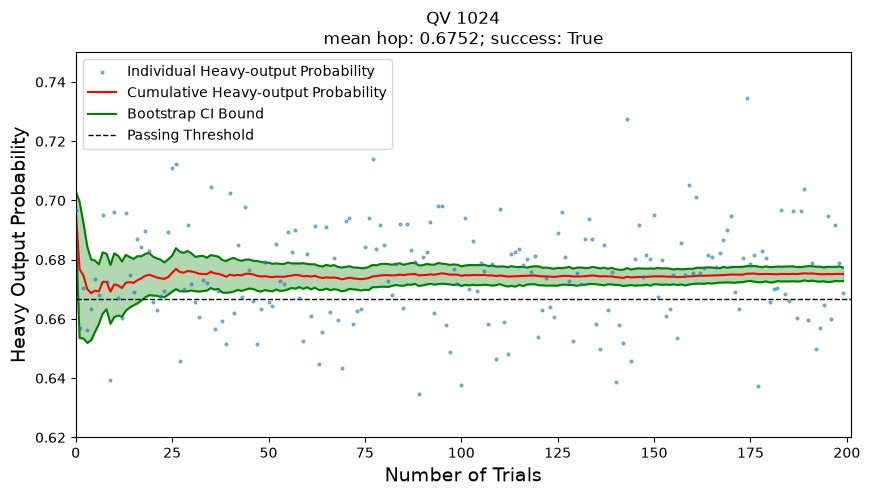

In [52]:
hops = job_hops(res_termeas_dd, ideal_probs)
plot_hop_accumulative(hops, len(hops)*[shots], 1024)

In [66]:
res_lk = res_termeas_dd_lk
collected_hops = []
lk_collected_hops = []
ps_shots = []

for i in range(len(res_lk)):
    cname = list(res_lk[i].data.keys())[0]
    lk_name = list(res_lk[i].data.keys())[1]
    bs_list = res_lk[i].data[cname].get_bitstrings()
    lk_bs_list = res_lk[i].data[lk_name].get_bitstrings()
    new_bs_list = []
    for j in range(len(bs_list)):
        if unequal_bits_ps(bs_list[j], lk_bs_list[j]):
            new_bs_list.append(bs_list[j])
    cts = Counter(bs_list)
    cts_ps = Counter(new_bs_list)
    ps_shots.append(sum(cts_ps.values()))
    collected_hops.append(hop(cts, get_ideal_probabilities(circuits_orig[i])))
    lk_collected_hops.append(hop(cts_ps, get_ideal_probabilities(circuits_orig[i])))

print(f'Raw QV: {np.array(collected_hops).mean()}')
print(f'After Leakage-Post-Selection: {np.array(lk_collected_hops).mean()}')

Raw QV: 0.6768080000000001
After Leakage-Post-Selection: 0.6818211442434472


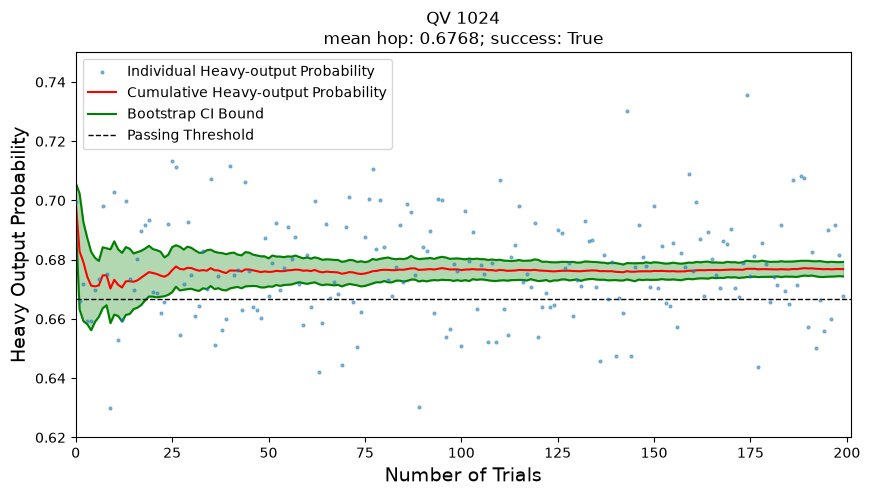

In [67]:
plot_hop_accumulative(collected_hops, len(collected_hops)*[shots], 1024)

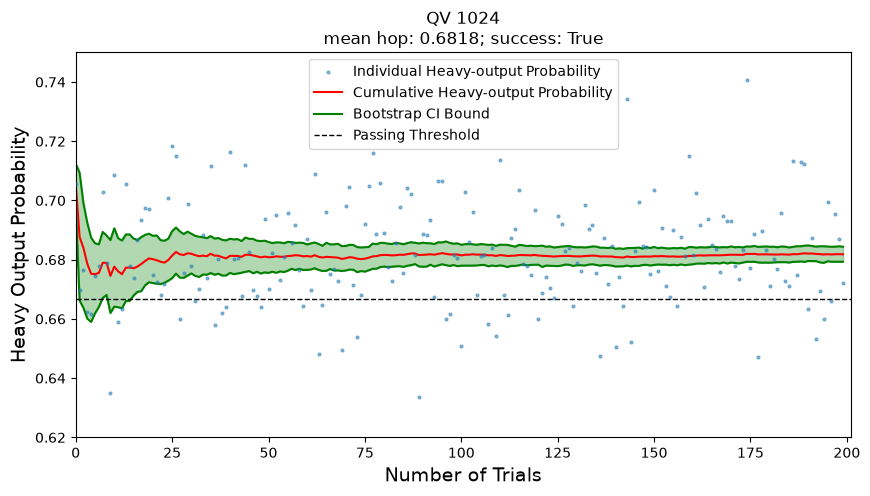

In [68]:
plot_hop_accumulative(lk_collected_hops, ps_shots, 1024)

In [69]:
with open('QV1024_phoenix_resultobj_jobID_dbrohhnv5hds73di50mg.pickle', 'wb') as f:
    pickle.dump(res_termeas_dd, f) 


In [70]:
with open('QV1024_phoenix_resultobj_jobID_dbrohshabdes73fqb960.pickle', 'wb') as f:
    pickle.dump(res_termeas_dd_lk, f) 